
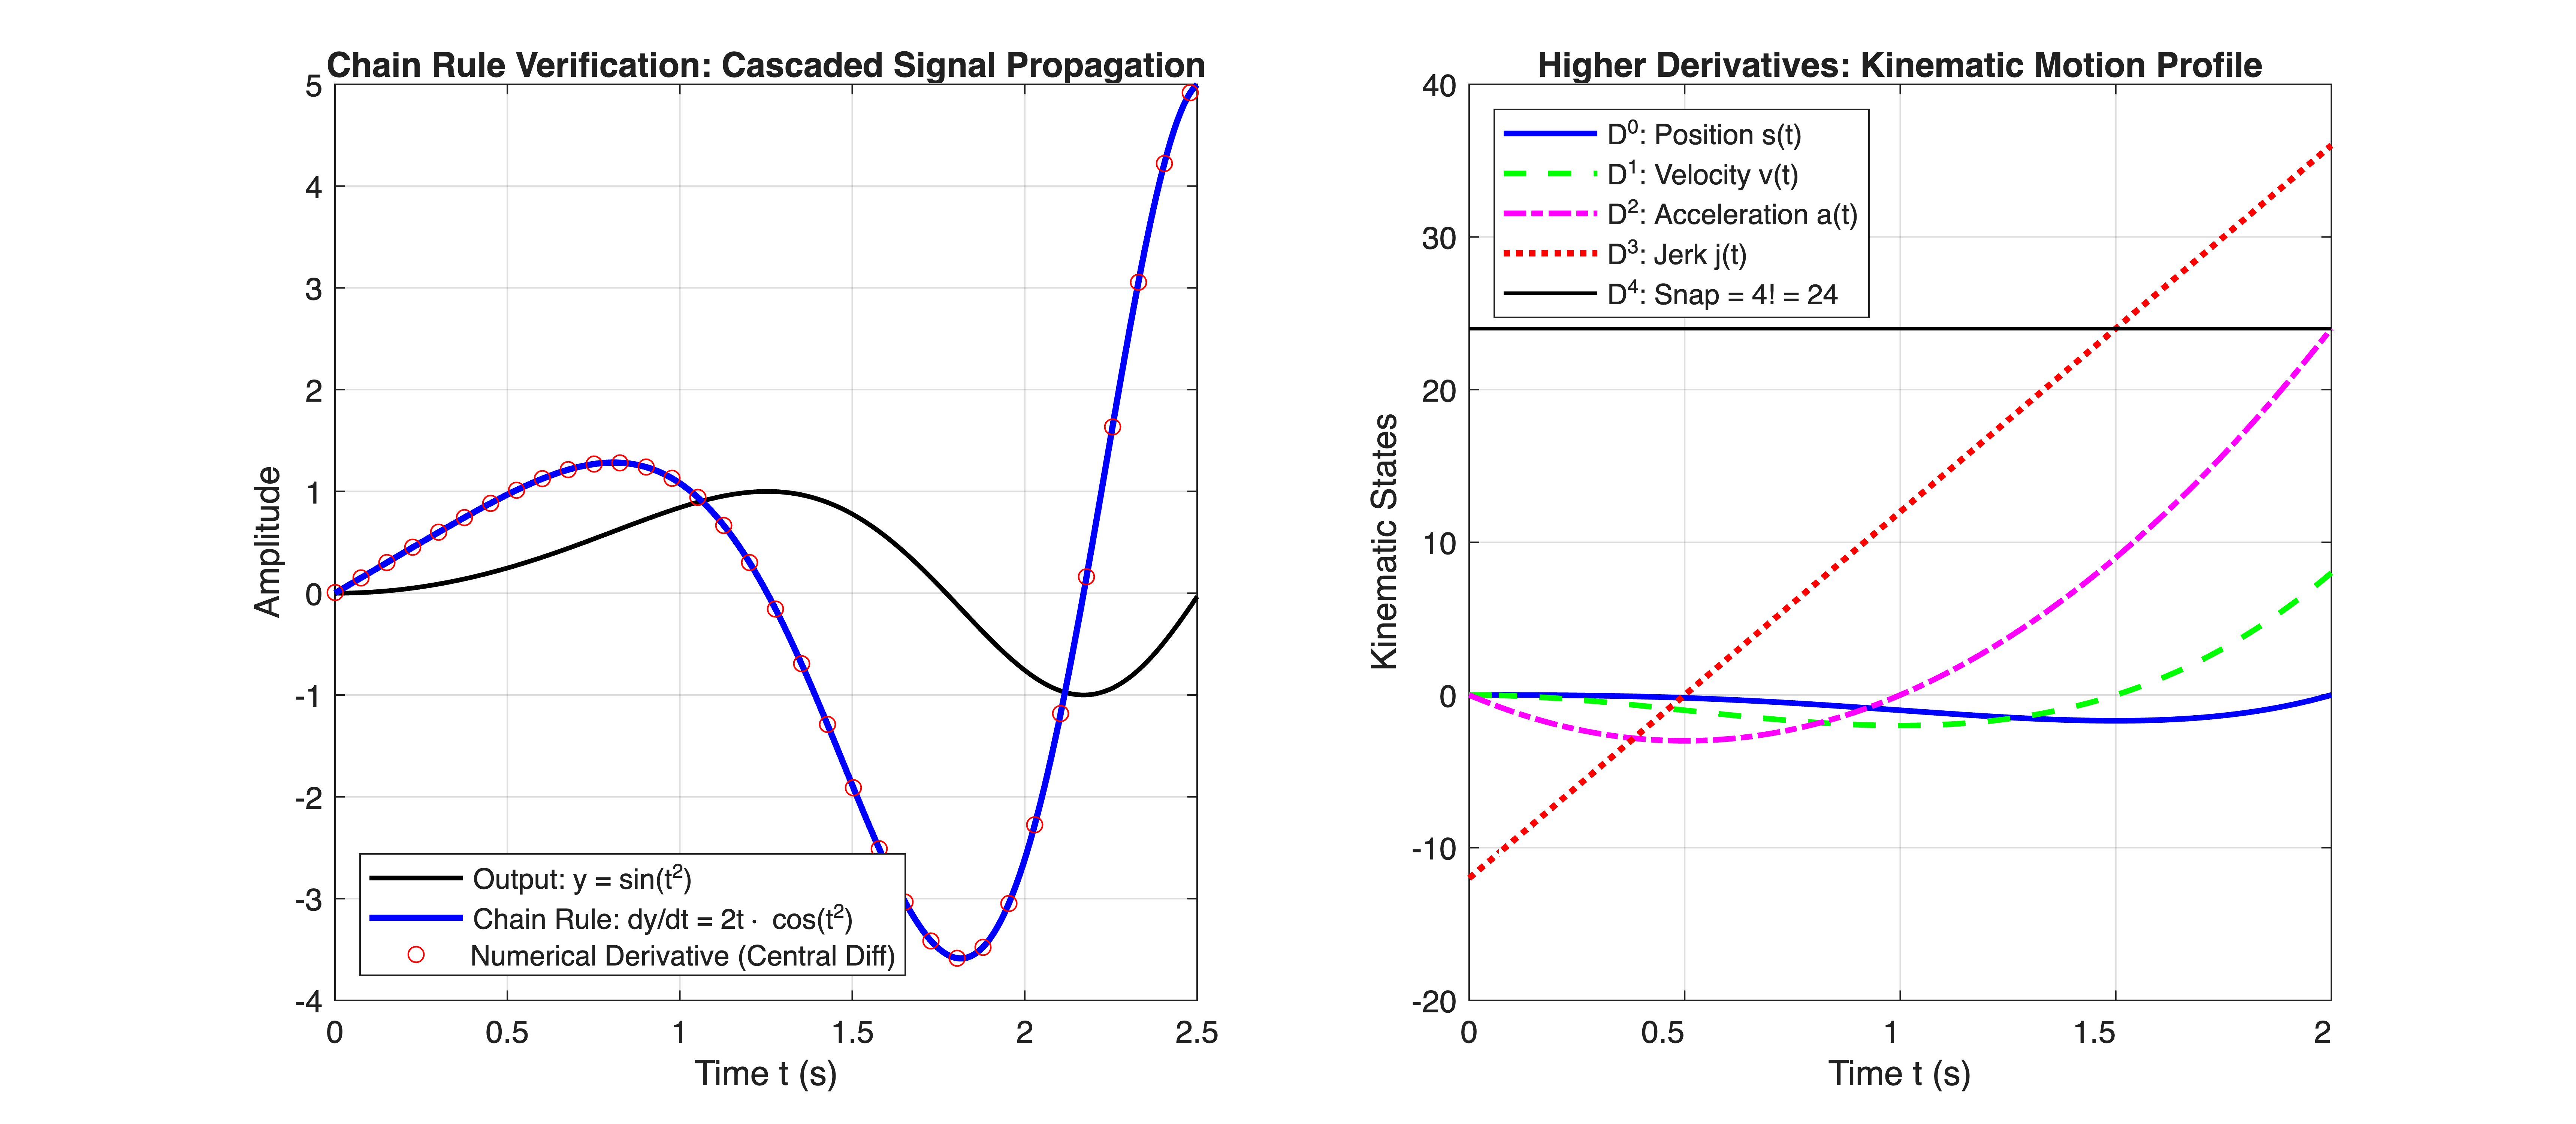

In [1]:
%% MIT 18.01 Lecture 4: Chain Rule and Higher Derivatives Simulation
% Mathematical Tool Application: Evaluates derivative propagation across cascaded
% subsystems (Jacobian chain product) and generates higher-order kinematic profiles
% (velocity, acceleration, jerk) for trajectory generation and feedforward control.


clear; clc; close all;


%% Part 1: Chain Rule Verification for Composite Signal y = sin(t^2)
% System definition: x = g(t) = t^2, y = f(x) = sin(x)
t_span = linspace(0, 2.5, 500);


% Inner and outer mappings
x_state = t_span.^2;               % Intermediate variable: g(t)
y_output = sin(x_state);           % Composite output: f(g(t))


% Analytic derivatives via Chain Rule: dy/dt = (dy/dx) * (dx/dt)
dx_dt = 2 * t_span;
dy_dx = cos(x_state);
dy_dt_analytic = dy_dx .* dx_dt;   % 2*t * cos(t^2)


% Numerical verification via central finite difference
dt = t_span(2) - t_span(1);
dy_dt_numerical = gradient(y_output, dt);


figure('Color', 'w', 'Position', [100, 100, 1100, 480]);


subplot(1, 2, 1);
plot(t_span, y_output, 'k-', 'LineWidth', 1.5, 'DisplayName', 'Output: y = sin(t^2)'); hold on;
plot(t_span, dy_dt_analytic, 'b-', 'LineWidth', 2, 'DisplayName', 'Chain Rule: dy/dt = 2t\cdot cos(t^2)');
plot(t_span(1:15:end), dy_dt_numerical(1:15:end), 'ro', 'MarkerSize', 5, ...
    'DisplayName', 'Numerical Derivative (Central Diff)');
grid on;
xlabel('Time t (s)');
ylabel('Amplitude');
title('Chain Rule Verification: Cascaded Signal Propagation');
legend('Location', 'southwest');
%% Part 2: Higher Derivatives of Polynomial Trajectory (Jerk Profile)
% Trajectory definition: s(t) = t^4 - 2*t^3 (Demonstrates D^1 to D^4)
t_traj = linspace(0, 2.0, 400);


pos = t_traj.^4 - 2 * t_traj.^3;                   % D^0: Position s(t)
vel = 4 * t_traj.^3 - 6 * t_traj.^2;               % D^1: Velocity v(t) = s'(t)
acc = 12 * t_traj.^2 - 12 * t_traj;                % D^2: Acceleration a(t) = s''(t)
jrk = 24 * t_traj - 12;                            % D^3: Jerk j(t) = s'''(t)
snp = 24 * ones(size(t_traj));                     % D^4: Snap = 4! = 24 (Constant)


subplot(1, 2, 2);
plot(t_traj, pos, 'b-',  'LineWidth', 1.8, 'DisplayName', 'D^0: Position s(t)'); hold on;
plot(t_traj, vel, 'g--', 'LineWidth', 1.8, 'DisplayName', 'D^1: Velocity v(t)');
plot(t_traj, acc, 'm-.', 'LineWidth', 1.8, 'DisplayName', 'D^2: Acceleration a(t)');
plot(t_traj, jrk, 'r:',  'LineWidth', 2.0, 'DisplayName', 'D^3: Jerk j(t)');
plot(t_traj, snp, 'k-',  'LineWidth', 1.2, 'DisplayName', 'D^4: Snap = 4! = 24');


grid on;
xlabel('Time t (s)');
ylabel('Kinematic States');
title('Higher Derivatives: Kinematic Motion Profile');
legend('Location', 'northwest');